In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pickle as pickle
import os
import import_ipynb
from matplotlib.patches import FancyArrowPatch
import ipynb.fs.full.ssiProjectModule as ssiMod
import importlib as imp
imp.reload(ssiMod)
import itertools
from matplotlib.collections import LineCollection as LC

In [2]:
theta_step = 2

main_dir = 'C:/Users/Carlo PARIS/00PhD Code/'
dat_dir_in_quad = 'C:/Users/Carlo PARIS/00PhD Code/0Paper plots/Figure1/'
dat_dir_in_trip = 'C:/Users/Carlo PARIS/00PhD Code/Triplet Sim/'

dat_dir_out = 'C:/Users/Carlo PARIS/00PhD Code/0Paper plots/Figure5/'
quad_title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
trip_title = f'Stretch_BioTriplets_multiplied_w_mean_g__theta_step={theta_step}_original_g_20250512_lower_area.pkl'

with open(dat_dir_in_quad+quad_title, 'rb') as rick:
    data_dict_quad = pickle.load(rick)
with open(dat_dir_in_trip+trip_title, 'rb') as rick:
    data_dict = pickle.load(rick)

bio_idx = np.where(data_dict['all_multipliers']==1.15)[0][0]
stim = np.arange(0,360,theta_step)

In [3]:
print(data_dict.keys())

dict_keys(['all_multipliers', 'all_triplet_combos', 'all_triplets_parameters', 'all_ssis', 'all_widths'])


In [4]:
maxMin_width_idx = data_dict['all_ssis'].min(axis = 2).argmax(axis=1)
maxAvg_width_idx = data_dict['all_ssis'].mean(axis = 2).argmax(axis=1)

maxMin_width_fwhm = np.array([data_dict['all_widths'][i,j] for i,j in enumerate(maxMin_width_idx)])
maxAvg_width_fwhm = np.array([data_dict['all_widths'][i,j] for i,j in enumerate(maxAvg_width_idx)])

fwhm = data_dict['all_widths'].mean(axis=2)
bio_fwhms = data_dict['all_widths'][:,bio_idx,:].round()

maxMin_SSI = np.array([data_dict['all_ssis'].min(axis = 2)[i,el] for i, el in enumerate(maxMin_width_idx)])
maxAvg_SSI = np.array([data_dict['all_ssis'].mean(axis = 2)[i,el] for i, el in enumerate(maxAvg_width_idx)])

# calculate the percantage of loss wirth respect to the global optimum !! 

perc_loss_maxmin = (maxMin_SSI-data_dict['all_ssis'].min(axis=2)[:,bio_idx])#/maxMin_SSI*100
perc_loss_maxavg = (maxAvg_SSI-data_dict['all_ssis'].mean(axis=2)[:,bio_idx])#/maxAvg_SSI*100

min_w_diffs = data_dict['all_widths'].mean(axis=2)[:,bio_idx]-\
                maxMin_width_fwhm.mean(axis=1)
avg_w_diffs = data_dict['all_widths'].mean(axis=2)[:,bio_idx]-\
                maxAvg_width_fwhm.mean(axis=1)

##  ORIGINAL ARRAYS
title_add = 'original_array'

# NB: Do some smoothing !  -> savgol_filter or simple 3-pt filtering
ssi_min_filt = np.copy(data_dict['all_ssis'].min(axis=2))
ssi_avg_filt = np.copy(data_dict['all_ssis'].mean(axis=2))

# GET OPTIMA FOLLOWING MIN_SSI CURVE
optima_min = []
cutoff_width = 180
for i,ssi_evol_raw in enumerate(data_dict['all_ssis'].min(axis=2)):
    ssi_min_filt = ssi_evol_raw
    absolute_last = len(ssi_min_filt)-1
#     last = min(np.where(np.any(data_dict['all_quad_fwhm'][i]<=cutoff_width, axis=1))[0][-1], ssi_min_filt.shape[1]-1)
    last = min(np.where(data_dict['all_widths'][i].mean(axis=1)<=cutoff_width)[0][-1], absolute_last)
    go1=3
    while go1>0 and last>0:
        minSSI_diff = (ssi_min_filt[last-1]-ssi_min_filt[last])
#         avgSSI_diff = (ssi_avg_filt[i,last-1]-ssi_avg_filt[i,last])        
        if minSSI_diff <= 0:#ssi_evol_raw.min(axis=1).std(axis=0)/100:
            go1 -= 1
#         else:
#             go1 = 3
        if not go1:
            optima_min += [last+2]
        last -= 1

optima_min = np.array(optima_min)
perc_loss_maxmin_crawl = np.array([data_dict['all_ssis'].min(axis=2)[i,el] \
                        for i,el in enumerate(optima_min)])\
                        -data_dict['all_ssis'].min(axis=2)[:,bio_idx]
optima_widths_min = np.array([data_dict['all_widths'][i,el].mean() for i,el in enumerate(optima_min)])

# large_quad = np.squeeze(np.argwhere(data_dict['all_quad_fwhm'][:,bio_idx,:].mean(axis=1)-optima_widths<-50))
# print(large_quad.shape)

# GET OPTIMA FILLOWING AVG_SSI CURVE
optima_avg = []
for i,ssi_evol_raw in enumerate(data_dict['all_ssis'].mean(axis=2)):
    ssi_avg_filt = ssi_evol_raw
    absolute_last = len(ssi_avg_filt)-1
#     last = min(np.where(np.all(data_dict['all_quad_fwhm'][i]<=cutoff_width, axis=1))[0][-1], ssi_min_filt.shape[1]-1)
    last = min(np.where(data_dict['all_widths'][i].mean(axis=1)<=cutoff_width)[0][-1], absolute_last)
    
    go1=3
    while go1>0 and last>0:
#         minSSI_diff = (ssi_min_filt[i,last-1]-ssi_min_filt[i,last])
        avgSSI_diff = (ssi_avg_filt[last-1]-ssi_avg_filt[last])        
        if avgSSI_diff <= 0:#ssi_evol_raw.mean(axis=1).std(axis=0)/100:
            go1 -= 1
#         else:
#             go1 = 3
        if not go1:
            optima_avg += [last+2]
        last -= 1
        
optima_avg = np.array(optima_avg)
perc_loss_maxavg_crawl = np.array([data_dict['all_ssis'].mean(axis=2)[i,el] \
                        for i,el in enumerate(optima_avg)])\
                        -data_dict['all_ssis'].mean(axis=2)[:,bio_idx]
optima_widths_avg = np.array([data_dict['all_widths'][i,el].mean() for i,el in enumerate(optima_avg)])

In [103]:
# np.random.seed(11)
example_trip = 100#np.random.choice(data_dict['all_ssis'].shape[0])

print(data_dict['all_triplets_parameters'][example_trip])
print(data_dict['all_ssis'][example_trip, bio_idx].shape)

print(example_trip)
trip_tcs = np.array([ssiMod.FTVM(stim, *pars) for pars in \
                     data_dict['all_triplets_parameters'][example_trip]])/1.6
trip_ssi = np.array([ssiMod.MC_SSI(tc) for tc in trip_tcs])
print(trip_tcs.shape)


[[ 5.38885992e+02  1.22286301e+02  1.12533972e-01  1.62225036e+00
   4.15351731e+01]
 [ 5.63083658e+02  2.41351369e+02  3.13980000e-01  3.21456982e+00
   3.36230951e+01]
 [ 5.80529197e+02 -1.97772828e+01  3.78390932e-01  5.06283478e-01
   2.93558119e+01]]
(180,)
100
ok
ok
ok
(3, 180)


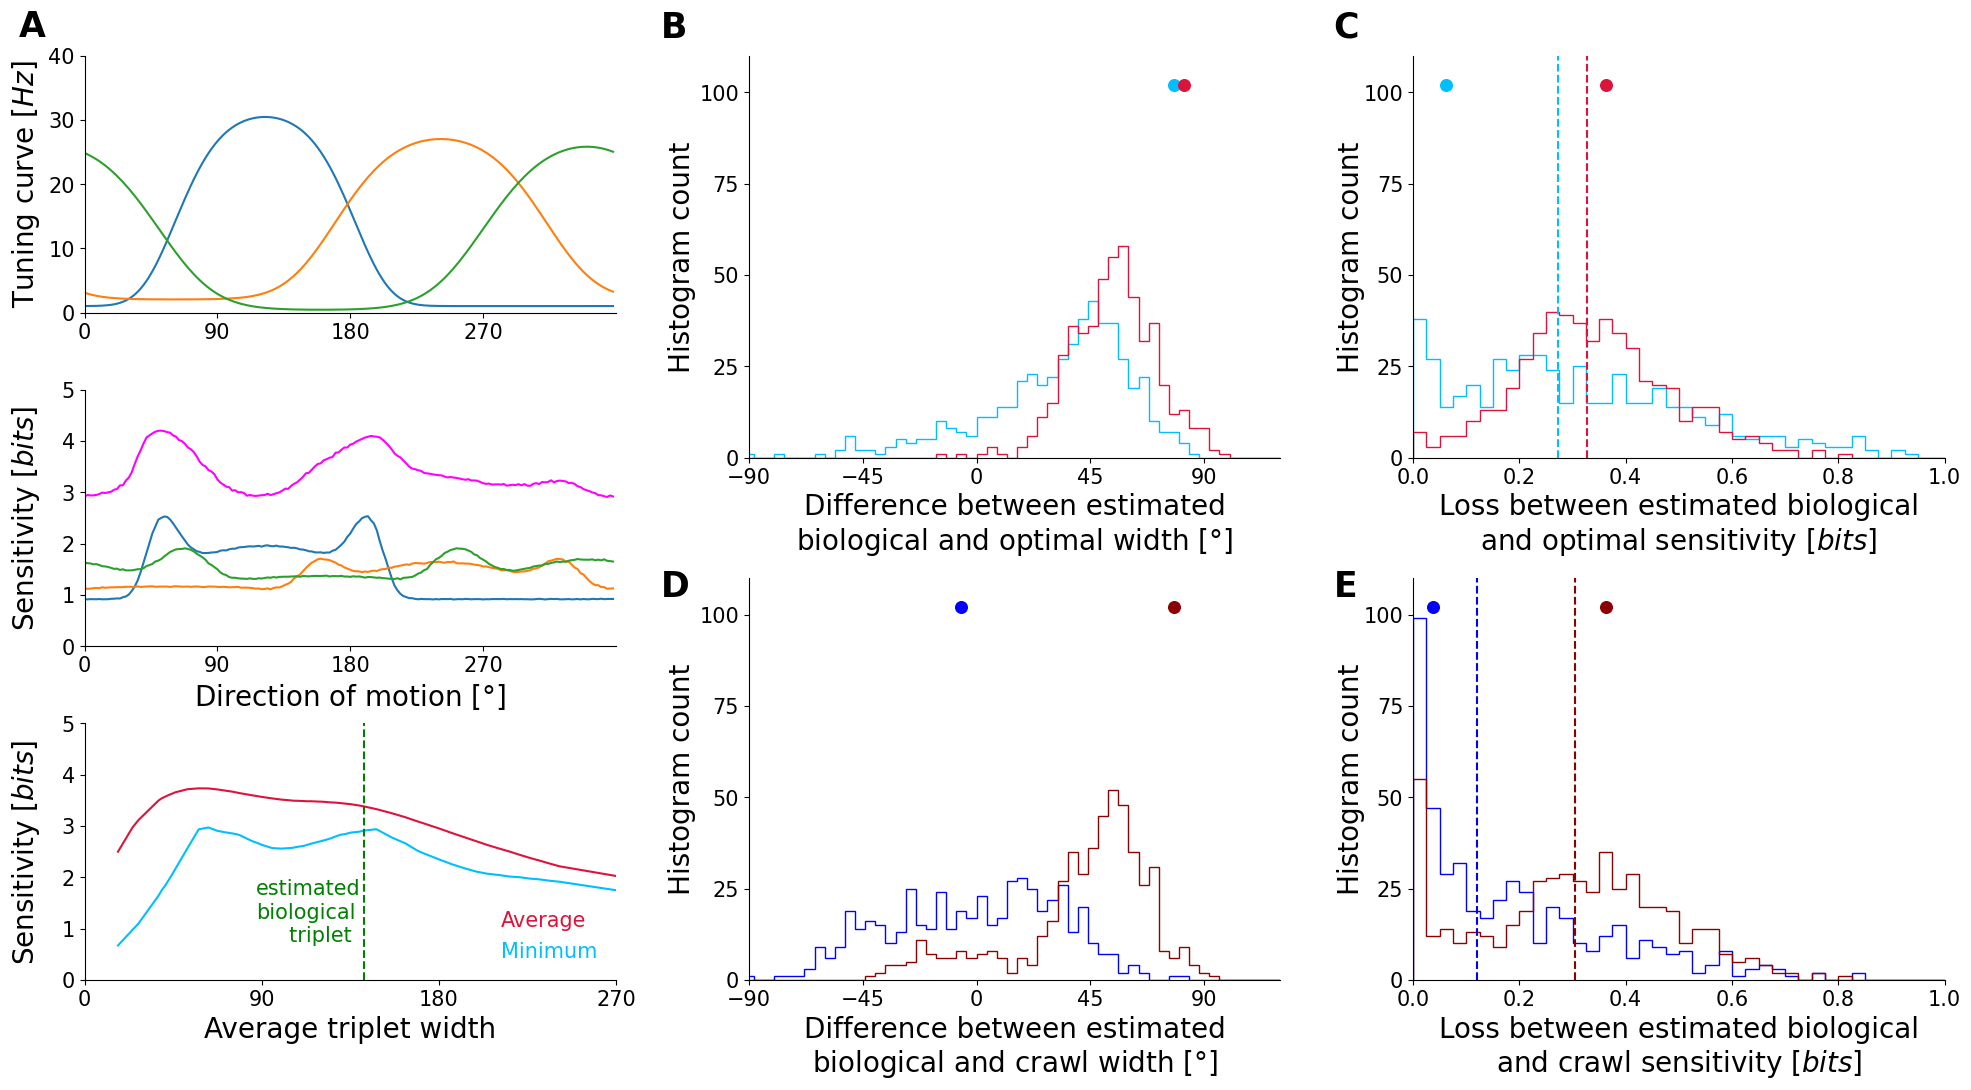

In [130]:
scatter_marker = ['o', 's']

fig = plt.figure(figsize = (24 , 12))
# gs = gridspec.GridSpec(5,3, wspace = 0.5, hspace = 0.2, height_ratios=(4,4,1,6,6))
gs = fig.add_gridspec(1,3, hspace = 0.4, wspace = 0.25)
gs01 = gs[0].subgridspec(3,1, hspace = 0.3)
gs02 = gs[1].subgridspec(2,1, hspace = 0.3)
gs03 = gs[2].subgridspec(2,1, hspace = 0.3)

ax_q1 = fig.add_subplot(gs01[0,0])
ax_q2 = fig.add_subplot(gs01[1,0])
ax_q3 = fig.add_subplot(gs01[2,0])

ax_gl_w_hist = fig.add_subplot(gs02[0,0])
ax_gl_loss_hist = fig.add_subplot(gs03[0,0])

ax_fig3_v_crawl_sc_min = fig.add_subplot(gs02[1])
ax_fig3_v_crawl_sc_avg = fig.add_subplot(gs03[1])

colors = ['blue', 'darkred']
cutoff_width = 180

ax_q1.plot(stim, trip_tcs.T)
# ax_q1.text(-45, 6.5, r'$\bf{A}$', fontsize = 25, transform = ax_q1.transData)
ax_q1.set_ylabel('Tuning curve [$Hz$]', size = 20)
ax_q1.set_xlim(0,360)
ax_q1.set_ylim(0,40)
ax_q1.set_xticks(np.arange(0,360,90))
ax_q1.set_yticks(np.arange(0,41,10))
ax_q1.text(-45, 43, r'$\bf{A}$', fontsize = 25, transform = ax_q1.transData)
ax_q1.tick_params(labelsize = 15)
ax_q1.yaxis.set_label_coords(-0.08, 0.5)


ax_q2.plot(stim, trip_ssi.T)
ax_q2.plot(stim, data_dict['all_ssis'][example_trip, bio_idx], color = 'magenta')
ax_q2.set_xlabel('Direction of motion [$\degree$]', size = 20)
ax_q2.set_ylabel('Sensitivity [$bits$]', size = 20)
ax_q2.set_xlim(0,360)
ax_q2.set_ylim(0,5)
ax_q2.set_xticks(np.arange(0,360,90))
ax_q2.set_yticks(np.arange(0,5.1,1))
ax_q2.tick_params(labelsize = 15)
ax_q2.yaxis.set_label_coords(-0.08, 0.5)

ax_q3.plot(data_dict['all_widths'][example_trip].mean(axis=1), \
           data_dict['all_ssis'][example_trip].mean(axis=1),color='crimson', label = 'Average')
ax_q3.plot(data_dict['all_widths'][example_trip].mean(axis=1), \
           data_dict['all_ssis'][example_trip].min(axis=1), color='deepskyblue', label = 'Minimum')
ax_q3.axvline(data_dict['all_widths'][example_trip, bio_idx].mean(), color='green',\
             linestyle = 'dashed')
ax_q3.text(data_dict['all_widths'][example_trip, bio_idx].mean()-55, 0.75, \
           'estimated\nbiological\n     triplet', color = 'green', size = 15, transform = ax_q3.transData)

ax_q3.set_xticks(np.arange(0,360,90))
ax_q3.set_xlim(0,270)
ax_q3.set_yticks(np.arange(0,5.1,1))
ax_q3.set_ylim(0,5)
ax_q3.tick_params(labelsize = 15)
ax_q3.set_xlabel('Average triplet width', size =20)
ax_q3.set_ylabel('Sensitivity [$bits$]', size =20)
ax_q3.yaxis.set_label_coords(-0.08, 0.5)
ax_q3.legend(handlelength = 0, labelcolor = 'linecolor', \
             frameon = 0, fontsize = 15, loc = 'lower right')

min_w_diffs = data_dict['all_widths'].mean(axis=2)[:,bio_idx]-\
                maxMin_width_fwhm.mean(axis=1)
avg_w_diffs = data_dict['all_widths'].mean(axis=2)[:,bio_idx]-\
                maxAvg_width_fwhm.mean(axis=1)

min_w_hist = ax_gl_w_hist.hist(min_w_diffs, range = (-120,120), bins = 60, \
                               histtype = 'step', color = 'deepskyblue')
avg_w_hist = ax_gl_w_hist.hist(avg_w_diffs, range = (-120,120), bins = 60, \
                               histtype = 'step', color = 'crimson')


decreaseMin = 0
for i,el in enumerate(np.array([example_trip])):
    ax_gl_w_hist.scatter((min_w_hist[1][np.where(min_w_diffs[el]<=min_w_hist[1])[0][0]]+\
                min_w_hist[1][np.where(min_w_diffs[el]<=min_w_hist[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color ='deepskyblue', s= 70)
    
    ax_gl_w_hist.scatter((avg_w_hist[1][np.where(avg_w_diffs[el]<=avg_w_hist[1])[0][0]]+\
                avg_w_hist[1][np.where(avg_w_diffs[el]<=avg_w_hist[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color = 'crimson', s= 70)
    decreaseMin += 3
    

ax_gl_w_hist.set_xticks(np.arange(-90,91,45))
ax_gl_w_hist.set_yticks(np.arange(0,101,25))
ax_gl_w_hist.set_xlim(-90,120)
ax_gl_w_hist.set_ylim(0,110)
ax_gl_w_hist.set_xlabel('Difference between estimated\n'+r'biological and optimal width [$\degree$]', \
                         size = 20)
ax_gl_w_hist.yaxis.set_label_coords(-0.1, 0.5)
ax_gl_w_hist.set_ylabel('Histogram count', size = 20)
ax_gl_w_hist.tick_params(labelsize = 15)
ax_gl_w_hist.text(-125, 115, r'$\bf{B}$', fontsize = 25, \
                  transform = ax_gl_w_hist.transData)


loc_loss_min = ax_gl_loss_hist.hist(perc_loss_maxmin, range=(0,1), bins = 40,\
                              histtype= 'step', color = 'deepskyblue')
loc_loss_avg = ax_gl_loss_hist.hist(perc_loss_maxavg, range=(0,1), bins = 40,\
                              histtype= 'step', color = 'crimson')
ax_gl_loss_hist.axvline(np.median(perc_loss_maxmin), linestyle = 'dashed', \
                              color =  'deepskyblue')
ax_gl_loss_hist.axvline(np.median(perc_loss_maxavg), linestyle = 'dashed', \
                              color = 'crimson')

ax_gl_loss_hist.set_xticks(np.arange(0,1.1, 0.2), labelsize = 20)
ax_gl_loss_hist.set_yticks(np.arange(0,101, 25))
ax_gl_loss_hist.set_xlim(0,1)
ax_gl_loss_hist.set_ylim(0,110)
ax_gl_loss_hist.yaxis.set_label_coords(-0.6, 0.5)
ax_gl_loss_hist.set_ylabel('Histogram count', size = 20)
ax_gl_loss_hist.set_xlabel('Loss between estimated biological\n'+\
                            r'and optimal sensitivity [$bits$]', size = 20)
ax_gl_loss_hist.tick_params(labelsize = 15)

decreaseMin = 0
for i,el in enumerate(np.array([example_trip])):    
    ax_gl_loss_hist.scatter((loc_loss_min[1][np.where(perc_loss_maxmin[el]<=loc_loss_min[1])[0][0]]+\
                loc_loss_min[1][np.where(perc_loss_maxmin[el]<=loc_loss_min[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color = 'deepskyblue', s= 70)
    ax_gl_loss_hist.scatter((loc_loss_avg[1][np.where(perc_loss_maxavg[el]<=loc_loss_avg[1])[0][0]]+\
                loc_loss_avg[1][np.where(perc_loss_maxavg[el]<=loc_loss_avg[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color = 'crimson', s= 70)
    decreaseMin += 6

ax_gl_loss_hist.text(-0.15, 115, r'$\bf{C}$', fontsize = 25, \
                  transform = ax_gl_loss_hist.transData)
ax_gl_loss_hist.yaxis.set_label_coords(-0.09, 0.5)


ax_fig3_v_crawl_sc_min.tick_params(labelsize = 15)
ax_fig3_v_crawl_sc_avg.tick_params(labelsize = 15)
ax_fig3_v_crawl_sc_min.yaxis.set_label_coords(-0.01, 0.5)



min_w_diffs = data_dict['all_widths'].mean(axis=2)[:,bio_idx]-optima_widths_min
avg_w_diffs = data_dict['all_widths'].mean(axis=2)[:,bio_idx]-optima_widths_avg

min_w_crawl_hist = ax_fig3_v_crawl_sc_min.hist(min_w_diffs, range = (-120,120),\
                            bins = 60, color = colors[0], histtype = 'step')
avg_w_crawl_hist = ax_fig3_v_crawl_sc_min.hist(avg_w_diffs, range = (-120,120),\
                            bins = 60, color = colors[1], histtype = 'step')
# ax_fig3_v_crawl_sc_min.axvline(np.median(perc_loss_maxmin), linestyle = 'dashed', \
#                               color = 'deepskyblue')
# ax_fig3_v_crawl_sc_min.axvline(np.median(perc_loss_maxmin_crawl), linestyle = 'dashed', \
#                               color = colors[0])
decreaseMin = 0
for i,el in enumerate(np.array([example_trip])):
    ax_fig3_v_crawl_sc_min.scatter((min_w_crawl_hist[1][np.where(min_w_diffs[el]<=min_w_crawl_hist[1])[0][0]]+\
                min_w_crawl_hist[1][np.where(min_w_diffs[el]<=min_w_crawl_hist[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color = colors[0], s= 70)
    
    ax_fig3_v_crawl_sc_min.scatter((avg_w_crawl_hist[1][np.where(avg_w_diffs[el]<=avg_w_crawl_hist[1])[0][0]]+\
                avg_w_crawl_hist[1][np.where(avg_w_diffs[el]<=avg_w_crawl_hist[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color = colors[1], s= 70)
    decreaseMin += 3

ax_fig3_v_crawl_sc_min.set_xticks(np.arange(-90,120, 45))
ax_fig3_v_crawl_sc_min.set_yticks(np.arange(0,101, 25))
ax_fig3_v_crawl_sc_min.set_xlim(-90,120)
ax_fig3_v_crawl_sc_min.set_ylim(0,110)
ax_fig3_v_crawl_sc_min.set_xlabel('Difference between estimated\n'+r'biological and crawl width [$\degree$]', size = 20)
ax_fig3_v_crawl_sc_min.set_ylabel('Histogram count', size = 20)

ax_fig3_v_crawl_sc_min.text(-125, 105, r'$\bf{D}$', fontsize = 25, \
                  transform = ax_fig3_v_crawl_sc_min.transData)
ax_fig3_v_crawl_sc_min.yaxis.set_label_coords(-0.1, 0.5)


maxmin_hist = ax_fig3_v_crawl_sc_avg.hist(perc_loss_maxmin_crawl, range = (0,1),\
                            bins = 40, color = colors[0], histtype = 'step')
maxavg_hist = ax_fig3_v_crawl_sc_avg.hist(perc_loss_maxavg_crawl, range = (0,1),\
                            bins = 40, color = colors[1], histtype = 'step') 

ax_fig3_v_crawl_sc_avg.axvline(np.median(perc_loss_maxmin_crawl), linestyle = 'dashed', \
                              color =  colors[0])
ax_fig3_v_crawl_sc_avg.axvline(np.median(perc_loss_maxavg_crawl), linestyle = 'dashed', \
                              color = colors[1])

ax_fig3_v_crawl_sc_avg.set_xticks(np.arange(0,1.1, 0.2))
ax_fig3_v_crawl_sc_avg.set_yticks(np.arange(0,101,25))
ax_fig3_v_crawl_sc_avg.set_xlim(0,1)
ax_fig3_v_crawl_sc_avg.set_ylim(0,110)
ax_fig3_v_crawl_sc_avg.set_xlabel('Loss between estimated biological\n'+\
                            r'and crawl sensitivity [$bits$]', size = 20)
ax_fig3_v_crawl_sc_avg.text(-0.15, 105, r'$\bf{E}$', fontsize = 25, \
                  transform = ax_fig3_v_crawl_sc_avg.transData)
ax_fig3_v_crawl_sc_avg.yaxis.set_label_coords(-0.09, 0.5)
ax_fig3_v_crawl_sc_avg.set_ylabel('Histogram count', size = 20)

decreaseMin = 0
for i,el in enumerate(np.array([example_trip])):    
    ax_fig3_v_crawl_sc_avg.scatter((maxmin_hist[1][np.where(perc_loss_maxmin_crawl[el]<=maxmin_hist[1])[0][0]]+\
                maxmin_hist[1][np.where(perc_loss_maxmin_crawl[el]<=maxmin_hist[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color = colors[0], s= 70)
    ax_fig3_v_crawl_sc_avg.scatter((maxavg_hist[1][np.where(perc_loss_maxavg_crawl[el]<=maxavg_hist[1])[0][0]]+\
                maxavg_hist[1][np.where(perc_loss_maxavg_crawl[el]<=maxavg_hist[1])[0][0]-1])/2, 102-decreaseMin,\
              marker = scatter_marker[i], color = colors[1], s= 70)
    decreaseMin += 3

plt.savefig('Supplementary_figure_TripletSim.jpg', bbox_inches = 'tight', dpi=300)

2.969714337913576
2.918128151778262
